# Tail risk and Value at Risk

Historical and fitted Normal thresholds are compared for the US market,
Brent spot and EUR/USD, first within the estimation sample and then over a later holdout period.
The analysis uses daily observations for **2010–2025**.

For energy and FX, these are downside spot-change thresholds. A position-level VaR also
depends on the size and direction of the exposure and its trading conventions.

Data Sources:


- Equity market and value-weighted industry portfolios: [Ken French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html);
- EIA observations: FRED [Brent](https://fred.stlouisfed.org/series/DCOILBRENTEU) and [Henry Hub gas](https://fred.stlouisfed.org/series/DHHNGSP);
- FED Exchange rates: FRED [EUR](https://fred.stlouisfed.org/series/DEXUSEU),
[JPY](https://fred.stlouisfed.org/series/DEXJPUS) and
[GBP](https://fred.stlouisfed.org/series/DEXUSUK).

## Libraries


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

## Data


In [2]:
# Load daily observations and use dates as the index.
data = pd.read_csv(
    "daily_market_data.csv",
    index_col="date",
    parse_dates=True
)

# Keep the sample period used throughout the analysis.
data = data.loc["2010-01-01":"2025-12-31"]
display(data.head())

,Mkt-RF,RF,BusEq,Enrgy,Hlth,DCOILBRENTEU,DHHNGSP,DEXUSEU,DEXJPUS,DEXUSUK
date,,,,,,,,,,
2010-01-04,0.0169,0.0,0.0159,0.0300,0.0131,79.05,6.09,1.4419,92.55,1.6109
2010-01-05,0.0031,0.0,0.0000,0.0078,-0.0060,79.27,6.19,1.4402,91.48,1.6009
2010-01-06,0.0013,0.0,-0.0069,0.0094,0.0053,80.14,6.47,1.4404,92.53,1.6016
2010-01-07,0.0040,0.0,-0.0036,-0.0033,0.0013,80.57,7.51,1.4314,93.31,1.5912
2010-01-08,0.0033,0.0,0.0076,0.0045,0.0025,80.06,6.56,1.4357,92.70,1.5993


In [3]:
# Equity returns are already expressed in decimals (0.01 = 1%).
# Mkt-RF is the excess market return: add RF to recover the total return.
# Industry portfolios already contain total returns, including dividends.
# Drop dates with no equity observations; retain missing values in individual series.
equity_returns = pd.DataFrame({
    "US market": data["Mkt-RF"] + data["RF"],
    "Technology stocks": data["BusEq"],
    "Energy stocks": data["Enrgy"],
    "Healthcare stocks": data["Hlth"],
}).dropna(how="all")

# Energy columns contain spot prices, rather than returns.
# EUR and GBP are quoted in USD per unit of foreign currency.
# Invert JPY per USD so all three exchange rates use the same convention.
# A rise in an exchange rate then indicates appreciation against the dollar.
spot_levels = pd.DataFrame({
    "Brent spot": data["DCOILBRENTEU"],
    "Natural gas spot": data["DHHNGSP"],
    "EUR in USD": data["DEXUSEU"],
    "JPY in USD": 1 / data["DEXJPUS"],
    "GBP in USD": data["DEXUSUK"],
})

## Total and excess returns

The **total return** measures an investment's gain or loss over a period, including dividends.
The **excess return** measures how much this return exceeds the risk-free return
over the same period:

$$
R_t^e = R_t - R_t^f.
$$

For example, a daily total return of 1.00% and a daily risk-free return of 0.02%
give an excess return of 0.98%. A negative excess return means the investment
underperformed the risk-free asset; its total return can still be positive.

In the supplied Ken French data, `Mkt-RF` is the excess return on the US market
and `RF` is the risk-free return. The data preparation above recovers the total market return:

$$
R_t^m = R_t^{m,e} + R_t^f = \text{Mkt-RF}_t + \text{RF}_t.
$$

The tail analysis uses total equity returns. The industry portfolio columns already provide total returns.

## Simple returns

For a positive level $P_t$, the simple return is the change relative to the preceding level:

$$
R_t=\frac{P_t-P_{t-1}}{P_{t-1}}=\frac{P_t}{P_{t-1}}-1.
$$

A decimal return of 0.01 means 1%. The tail analysis uses simple returns for equities
and proportional spot-price changes for energy and currencies.

In [4]:
spot_returns = {}

for name in spot_levels:
    # Remove missing levels within each spot or FX series before calculating changes.
    prices = spot_levels[name].dropna()

    # Align the preceding available observation, rather than the preceding calendar day.
    # Weekends, holidays or missing-data gaps can make the interval longer than one day.
    # The first observation has no preceding price, so its return remains missing.
    previous_prices = prices.shift(1)

    # Simple return: (current price - previous price) / previous price.
    spot_returns[name] = (prices - previous_prices) / previous_prices

spot_returns = pd.DataFrame(spot_returns).sort_index()

# Equity values already are simple returns; join all series by their observation dates.
returns = pd.concat([equity_returns, spot_returns], axis=1, sort=True).sort_index()
display((100 * returns.head()).round(3))

,US market,Technology stocks,Energy stocks,Healthcare stocks,Brent spot,Natural gas spot,EUR in USD,JPY in USD,GBP in USD
date,,,,,,,,,
2010-01-04,1.69,1.59,3.00,1.31,NaN,NaN,NaN,NaN,NaN
2010-01-05,0.31,0.00,0.78,-0.60,0.278,1.642,-0.118,1.170,-0.621
2010-01-06,0.13,-0.69,0.94,0.53,1.098,4.523,0.014,-1.135,0.044
2010-01-07,0.40,-0.36,-0.33,0.13,0.537,16.074,-0.625,-0.836,-0.649
2010-01-08,0.33,0.76,0.45,0.25,-0.633,-12.650,0.300,0.658,0.509


## Historical and Normal thresholds

With $\alpha=0.01$, the **historical threshold** is the sample 1st percentile of returns.
The **Normal threshold** uses a fitted Normal distribution with the sample mean and
standard deviation:

$$
q_\alpha^N=\hat\mu+\hat\sigma\Phi^{-1}(\alpha).
$$

For an unlevered long equity position, a positive loss convention is:

$$
\mathrm{VaR}_{99\%}=-q_{0.01},
$$

when the threshold is negative. For example, a return threshold of −3% gives a 99% VaR
of 3% of the position's value. A 1% lower tail corresponds to a 99% confidence level.
VaR is neither a maximum loss nor an average loss beyond the cutoff.

A fitted Normal model matches the mean and volatility but can miss heavier (fat) tails
and extreme observations in the return distribution.

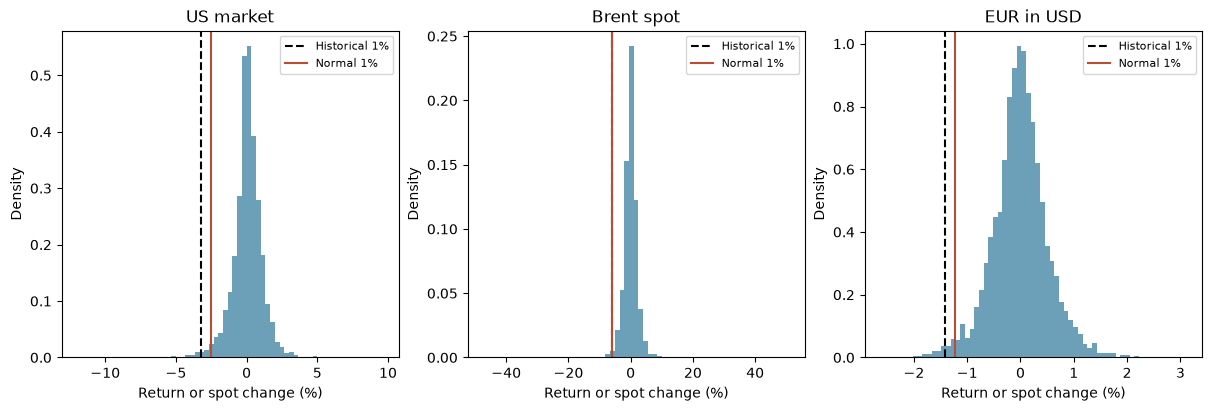

threshold (%)  observations  breaches  expected at 1%  \
series     model                                                               
US market  Historical        -3.2608          4024        41           40.24   
           Normal            -2.5511          4024        77           40.24   
Brent spot Historical        -5.9967          4046        41           40.46   
           Normal            -6.0489          4046        40           40.46   
EUR in USD Historical        -1.4163          4000        40           40.00   
           Normal            -1.2234          4000        76           40.00   

                       breach frequency (%)  
series     model                             
US market  Historical                1.0189  
           Normal                    1.9135  
Brent spot Historical                1.0133  
           Normal                    0.9886  
EUR in USD Historical                1.0000  
           Normal                    1.9000

In [5]:
# Compare the same three series using a 1% lower-tail probability.
selected = ["US market", "Brent spot", "EUR in USD"]
alpha = 0.01
rows = []
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, name in zip(axes, selected):
    x = returns[name].dropna()
    # Estimate the historical quantile and the fitted Normal quantile in return units.
    historical = x.quantile(alpha)
    normal = x.mean() + x.std(ddof=1) * stats.norm.ppf(alpha)
    # Count returns strictly below each threshold; display cutoffs in percent.
    for model, cutoff in {"Historical": historical, "Normal": normal}.items():
        rows.append({
            "series": name, "model": model, "threshold (%)": 100 * cutoff,
            "observations": len(x), "breaches": int((x < cutoff).sum()),
            "expected at 1%": alpha * len(x), "breach frequency (%)": 100 * (x < cutoff).mean(),
        })
    ax.hist(100 * x, bins=65, density=True, alpha=0.7, color="#2e789c")
    ax.axvline(100 * historical, color="black", ls="--", label="Historical 1%")
    ax.axvline(100 * normal, color="#ba4b35", label="Normal 1%")
    ax.set(title=name, xlabel="Return or spot change (%)", ylabel="Density")
    ax.legend(fontsize=8)
plt.show()
thresholds = pd.DataFrame(rows).set_index(["series", "model"])
display(thresholds.round(4))

The expected number of breaches under a correct 1% threshold is $0.01n$; the realised count
need not equal this expectation. The historical threshold is fitted to the same observations
used for the count, so its frequency is largely determined by quantile construction.
A fitted Normal cutoff can miss the observed tail even when it matches the mean and variance.

## Thresholds frozen before a holdout period

Estimation uses 2010–2019, and evaluation uses 2020–2025. Both cutoffs remain fixed during
evaluation, keeping later observations out of the estimates. Changes in dispersion and clustered
extremes can affect breach frequencies; this is a descriptive comparison of a static benchmark.


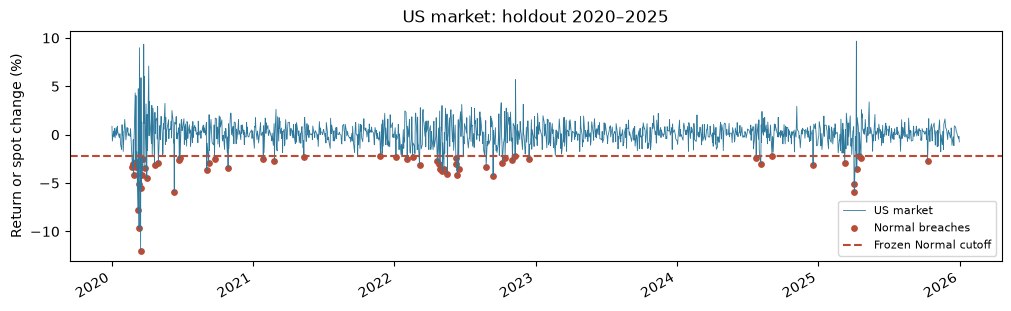

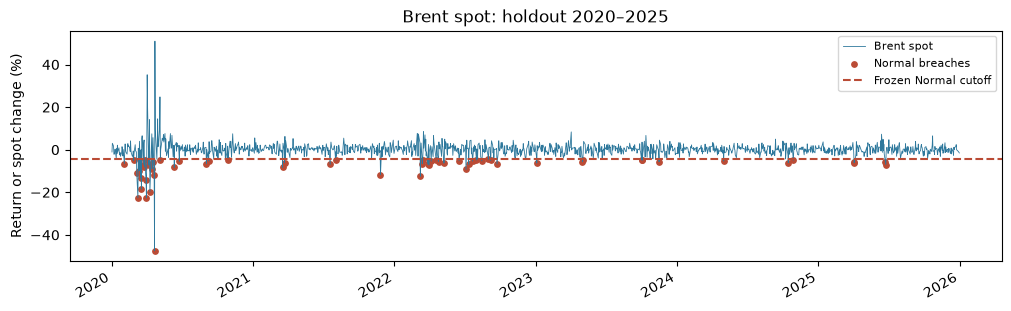

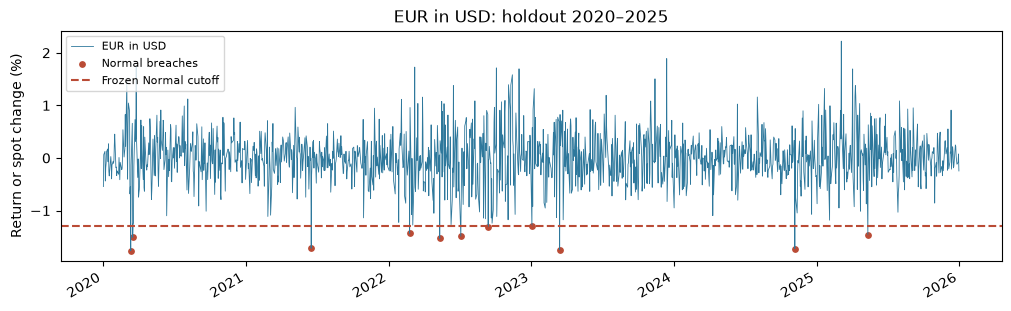

training n  test n  frozen threshold (%)  breaches  \
series     model                                                            
US market  Historical        2516    1508               -2.9025        34   
           Normal            2516    1508               -2.1739        59   
Brent spot Historical        2528    1518               -4.8562        55   
           Normal            2528    1518               -4.4445        60   
EUR in USD Historical        2501    1499               -1.4462         8   
           Normal            2501    1499               -1.2937        11   

                       expected at 1%  breach frequency (%)  
series     model                                             
US market  Historical           15.08                2.2546  
           Normal               15.08                3.9125  
Brent spot Historical           15.18                3.6232  
           Normal               15.18                3.9526  
EUR in USD Historical           14.99                0.5337  
           Normal               14.99                0.7338

In [6]:
holdout_rows = []
for name in selected:
    # Estimate using 2010–2019 and evaluate using the separate 2020–2025 sample.
    train = returns.loc[:"2019-12-31", name].dropna()
    test = returns.loc["2020-01-01":, name].dropna()
    # Freeze both thresholds: later observations do not enter the estimates.
    cutoffs = {
        "Historical": train.quantile(alpha),
        "Normal": train.mean() + train.std(ddof=1) * stats.norm.ppf(alpha),
    }
    # Count holdout breaches against each frozen threshold.
    for model, cutoff in cutoffs.items():
        hits = test < cutoff
        holdout_rows.append({
            "series": name, "model": model, "training n": len(train), "test n": len(test),
            "frozen threshold (%)": 100 * cutoff, "breaches": int(hits.sum()),
            "expected at 1%": alpha * len(test), "breach frequency (%)": 100 * hits.mean(),
        })
    fig, ax = plt.subplots(figsize=(10, 3), constrained_layout=True)
    (100 * test).plot(ax=ax, lw=0.6, color="#2e789c")
    # Highlight returns below the frozen Normal threshold.
    hits = test < cutoffs["Normal"]
    ax.scatter(test.index[hits], 100 * test[hits], s=15, color="#ba4b35", label="Normal breaches")
    ax.axhline(100 * cutoffs["Normal"], color="#ba4b35", ls="--", label="Frozen Normal cutoff")
    ax.set(title=f"{name}: holdout 2020–2025", ylabel="Return or spot change (%)", xlabel="")
    ax.legend(fontsize=8)
    plt.show()
holdout = pd.DataFrame(holdout_rows).set_index(["series", "model"])
display(holdout.round(4))

Holdout frequencies reflect both the shape of the later distribution and changes relative to
the estimation period. A fixed cutoff can become inadequate as dispersion changes.
The largest realised losses can also be substantially greater than the VaR quantile.
